# E68: Can the pass test on Qwen tell a good placement from a bad one, and can it pass anything?

*Independent check of the whole-update read and the opened masks: no bug, holds with caveats, applied here. `reports/reviews/2026-11-03_review_e68-ceiling.md`.*

## The answer

No split keeps the fine-tuned model's behaviour under the original model's masks. The test can fail a bad placement, on all four updates. It cannot pass one: adding the whole update, unmasked, closes at most 0.14 of the KL gap, where we predicted 0.85 or more. Least squares closing a tenth or less is therefore not evidence against least squares. On the two updates opened, the missing Δ alone does not explain the gap. Whether the masks would drop any such change is unread. What D1's test should be is open.


## What we were trying to test

`GOALS.md` asks whether a decomposition can stay faithful through a real update. D1 is that question on Qwen3-1.7B. It needs a test that can fail a bad placement of an update. This job also found out whether that test can pass a good one.

**The setting.** Each weight matrix is $W_0 = U V^\top + \Delta$. $U$ and $V$ hold the alive subcomponents' write and read vectors. Γ gives each subcomponent a causal importance $g$ at each position. The masked forward multiplies each subcomponent by $g$ and leaves Δ out. An update $\delta W$ is the fine-tune's change to the weights.

**The four updates.** All are saved states, nothing was trained here.

- The first fine-tune on GSM8K's human-written solutions, with no warm-up, at steps 10 and 100.
- The gold fine-tune: the same data, retrained with a warm-up at full precision, at step 100.
- The template fine-tune at step 100, read on its own 64 rows.

The other three read 128 maths rows. Every row has 256 tokens.

**The ruler.** Every state is read through the masked forward, with the masks fixed at those Γ gives on $W_0$'s forward. We call these W0's masks. Three KLs set the scale, each averaged over every position:

- $K$ is KL(fine-tuned model ‖ the state's masked forward).
- $K_D$ is that KL for do-nothing, which puts the whole update in Δ and so loses it here.
- $K_0$ is KL($W_0$ ‖ $W_0$'s masked forward), the damage the masks do to the unchanged model.

The **share of the KL gap closed** is $(K_D - K)/(K_D - K_0)$. Do-nothing reads 0. A state whose KL to the fine-tuned model is as small as $K_0$ reads 1. The **faithful line**, filed here, is $K \le 1.5\,K_0$, which on this axis sits between 0.88 and 0.98.

**The arms, and what each rules out.**

- *Often-on half:* the update placed on the half of each matrix's subcomponents that Γ often switches on. This should score well if the test can see good placement.
- *Rarely-on half:* the same update placed on the half Γ rarely switches on. A test with no power would score it like the often-on half.
- *Random change:* random weights scaled until their unmasked KL from $W_0$ matches the fine-tune's. This rules out credit for any change of that size.
- *Least-squares and adjoint splits:* the two candidates. Least squares sends the update's remainder to Δ, over a third of it. The scaled adjoint split leaves Δ almost untouched.
- *Whole update, unmasked:* Amendment 1's yardstick, not a map. Each matrix's output is the masked forward plus $x\,\delta W^\top$ for its input $x$, with no mask on the added term. We call it the ceiling; nothing proves that a placement cannot exceed it.
- *Opened masks:* Amendment 2. The mask becomes $g + t(1-g)$ for $t$ of 0.1, 0.5 and 1, with and without the whole update, on the first 32 rows of two updates. At $t = 1$ every subcomponent is fully on, so only Δ is missing.

A second ruler sits beside the KL. **Gain kept** is the state's drop in next-token NLL from $W_0$'s masked forward, as a share of the fine-tune's drop from clean $W_0$. Because the halves carry different amounts of the update, they are compared per unit carried: the share closed divided by the part of the update not in Δ.


## What we expected, and why

**The two halves would separate.** An earlier read gave 0.13 per unit carried for the often-on half against 0.004 for the rarely-on half, on the first fine-tune at step 10. We expected the same on the other updates, with less confidence on the template, whose KL is small.

**No split would reach the faithful line.** We held this firmly. Least squares was expected to read between 0.06 and 0.09 on the gold fine-tune, because an earlier read without moved read vectors gave 0.074.

**The state's own masks would not separate the halves.** Earlier KLs under masks from the state's own weights were nearly equal.

**The whole update would come close.** We filed a medium lean of 0.85 or more on the three updates read on maths rows. The thought was that adding everything back leaves only the masks' own damage. This is the prediction that reversed.

**Opening the masks would point at the masks, not at Δ.** Δ is small on the rows the decomposition was trained on, so we leaned that way.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_pass_test")
RES, FIG = ROOT / "results", ROOT / "figures"
SC = json.loads((RES / "score.json").read_text())
CEIL = json.loads((RES / "amend1" / "score.json").read_text())
OPEN = json.loads((RES / "amend1" / "open.json").read_text())
UPDATES = (("u1", "first fine-tune, step 10"), ("u2", "gold fine-tune, step 100"),
           ("u3", "template, step 100"), ("u4", "first fine-tune, step 100"))

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


## What we observed

### Does the test fail a bad placement, and does any split reach the faithful line?


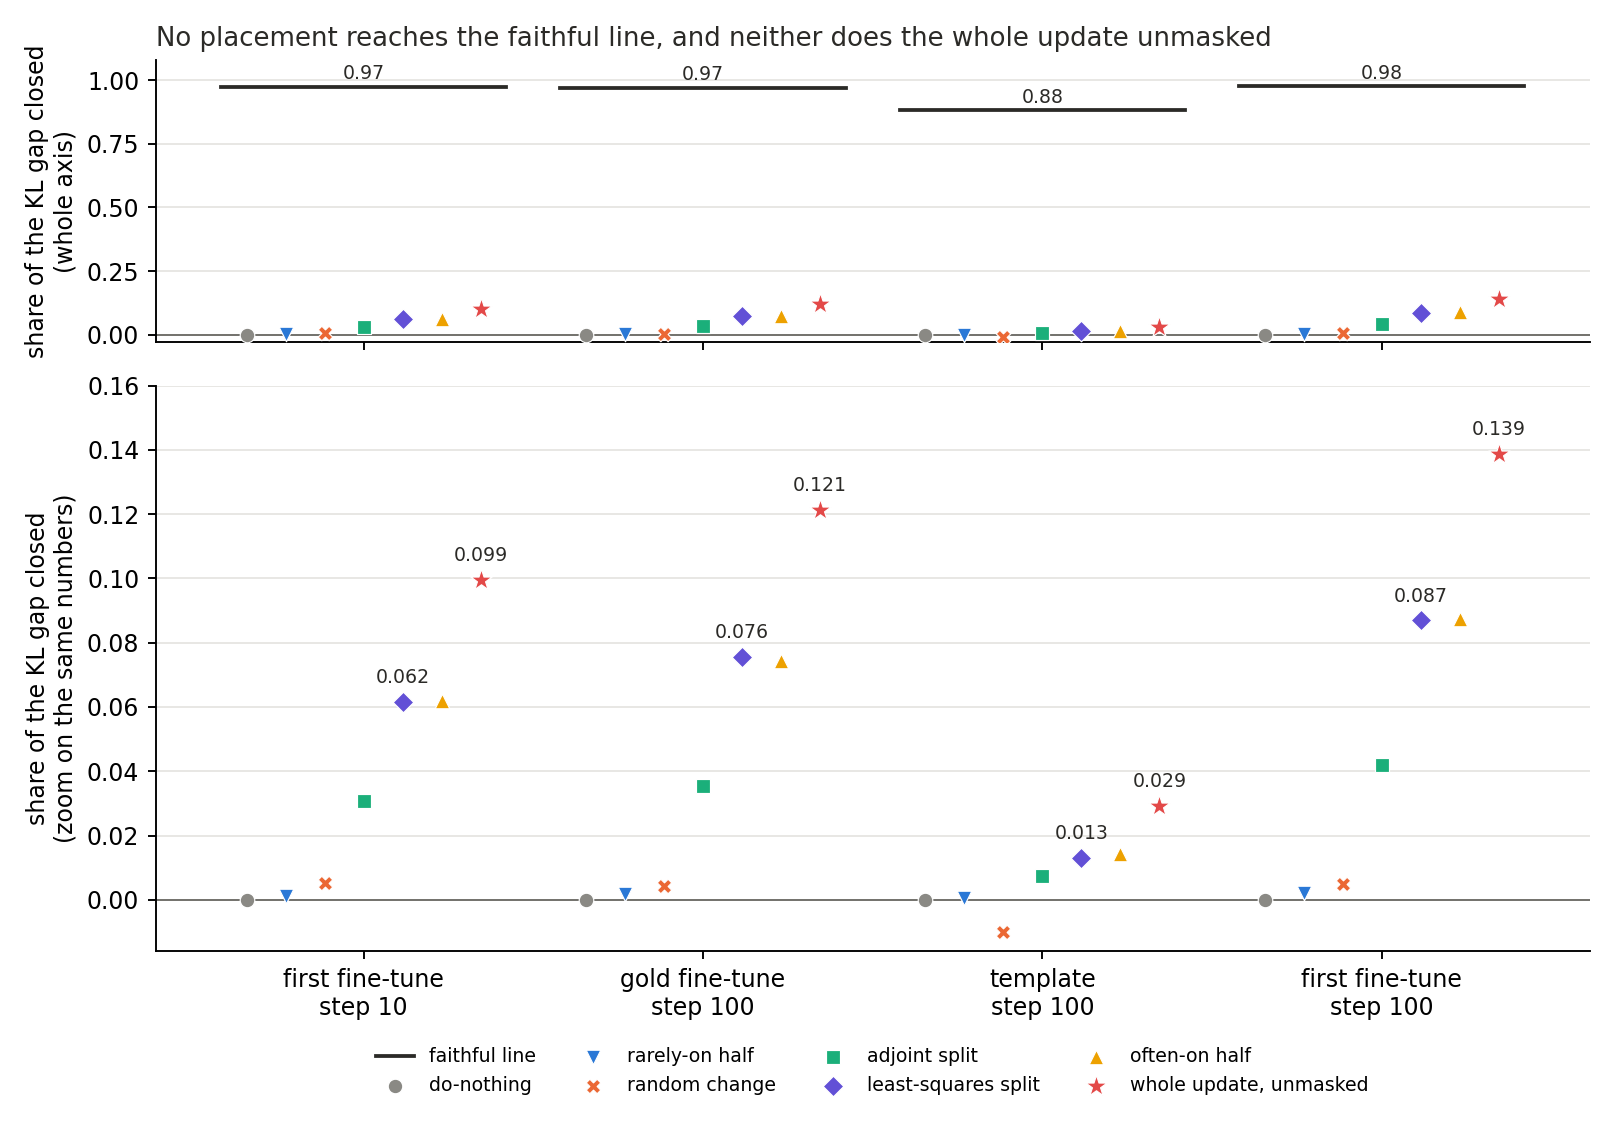

| update | often-on, per unit | rarely-on, per unit | random | least squares, per unit | adjoint, per unit |
|---|---|---|---|---|---|
| first fine-tune, step 10 | 0.129 | 0.004 | 0.005 | 0.097 | 0.031 |
| gold fine-tune, step 100 | 0.169 | 0.007 | 0.004 | 0.124 | 0.036 |
| template, step 100 | 0.030 | 0.001 | -0.010 | 0.020 | 0.008 |
| first fine-tune, step 100 | 0.185 | 0.008 | 0.005 | 0.138 | 0.042 |

In [2]:
show("gap_closed.png")
table(["update", "often-on, per unit", "rarely-on, per unit", "random", "least squares, per unit", "adjoint, per unit"],
      [[lab, *(f"{SC[u]['states'][s]['rho']:.3f}" for s in ("upper", "lower", "random", "ls", "adjoint"))] for u, lab in UPDATES])


**Reading it.** The test fails bad placements on all four updates, and no split is faithful on any of them. In the zoomed panel the often-on half sits well above the rarely-on half and the random change, which stay near do-nothing's 0. Per unit carried, the often-on half reads at least 20 times the rarely-on half on every update, and it beats the rarely-on half on every row. Least squares and the adjoint split land between these controls per unit carried, so both are labelled partial on all four updates. The top panel shows how far all of them are from the faithful line.


### Can the test pass anything at all?


In [3]:
rows = []
for u, lab in UPDATES:
    ls, c = SC[u]["states"]["ls"], CEIL[u]
    rows.append([lab, f"{ls['r2']:.3f}", f"{c['r2_C']:.3f}", f"{ls['gain_kept']:.3f}", f"{c['gain_C']:.3f}"])
table(["update", "KL share, least squares", "KL share, whole update", "gain, least squares", "gain, whole update"], rows)


| update | KL share, least squares | KL share, whole update | gain, least squares | gain, whole update |
|---|---|---|---|---|
| first fine-tune, step 10 | 0.062 | 0.099 | 0.175 | 0.258 |
| gold fine-tune, step 100 | 0.076 | 0.121 | 0.300 | 0.443 |
| template, step 100 | 0.013 | 0.029 | 0.010 | 0.022 |
| first fine-tune, step 100 | 0.087 | 0.139 | 0.325 | 0.477 |

**Reading it.** No, and this reversed what we filed. The red stars in the figure above show the whole update, added unmasked, closing 0.10, 0.12, 0.03 and 0.14 of the KL gap, in the figure's order. We had filed a medium lean of 0.85 or more on the three maths-row updates. The filed label on all four is "cannot pass". That is true of KL: the same read keeps 0.26, 0.44 and 0.48 of the gain on the maths-row updates, and 0.02 on the template. Both controls of this read were clean. With the added term at zero the forward reproduced do-nothing's KL. The same hook without masks rebuilt the fine-tuned model, to a KL under 2e-9.

So least squares closing a tenth or less is not evidence against least squares. On this ruler the whole update itself does little more: 0.076 against 0.121 on the gold fine-tune and 0.013 against 0.029 on the template. Least squares reaches about 0.62 of the whole update's KL share on the three maths-row updates, and about 0.68 of its gain. On the template it reaches 0.45 and 0.47.


### Does the missing Δ alone explain the gap?


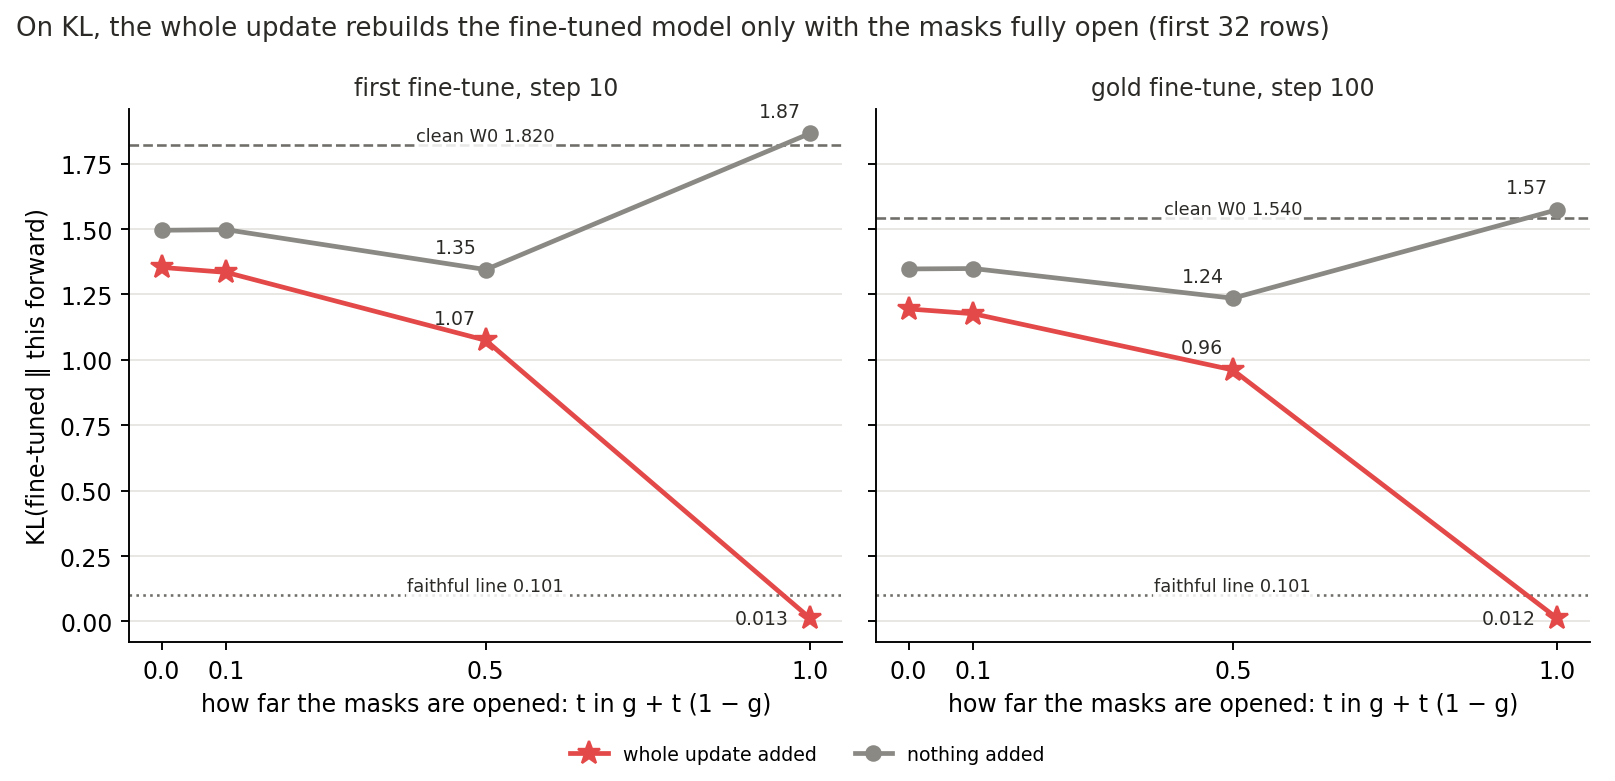

In [4]:
show("opening_kl.png")


**Reading it.** No, on the two updates opened, first 32 rows only. With every subcomponent fully on, the whole update added and Δ off, the KL reads 0.013 and 0.012. That is under the faithful line and about a hundredth of its value under W0's masks, so the filed rule's label is "masks". What this shows is that Δ's absence alone costs 0.013. It does not show that Δ would not help under the masks, because Δ on under the masks was never read. Half-open masks are not enough: the KL still reads 1.07 and 0.96 at $t = 0.5$.

Nothing yet separates "the masks drop any change of this size" from "the update needs parts the masks switch off". E72 reads a random change the same way. We did not read how far the half-open model sits from $W_0$, so we cannot say whether it is a working model. The template, which has the lowest reading, was not opened. We claim no mechanism.


### Does next-token NLL tell the same story as the KL?


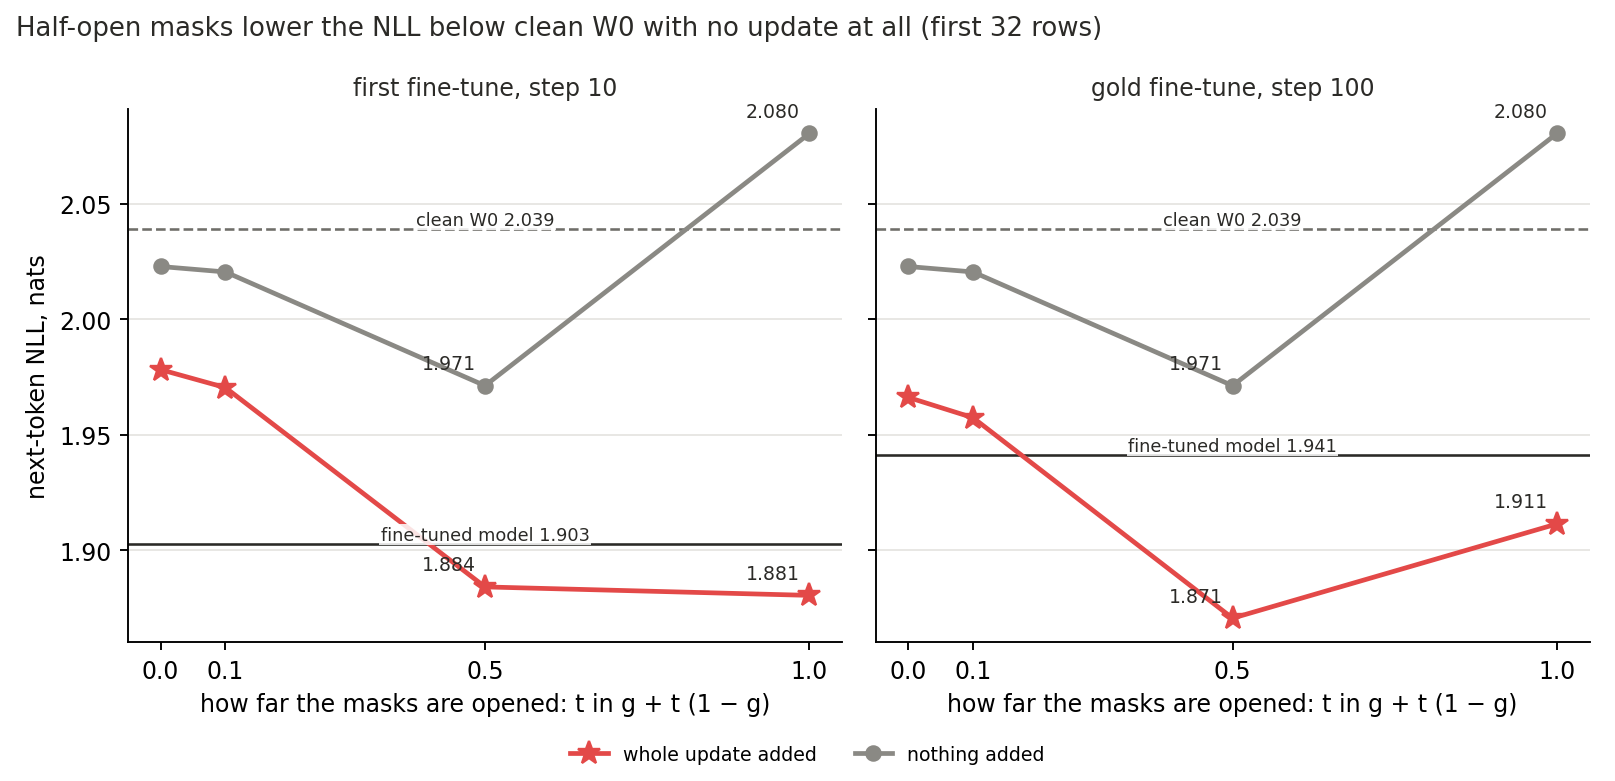

In [5]:
show("opening_nll.png")


**Reading it.** No, and we cannot explain the difference. This is an unfiled read from the same files. With nothing added, half-open masks bring the NLL to 1.971, below clean $W_0$'s 2.039. That is half of the first fine-tune's own drop on these rows, and no update is involved. With the whole update added at $t = 0.5$ the NLL reaches 1.884 and 1.871, below the fine-tuned model, while the KL to that model is still 1.07 and 0.96. So the two rulers disagree about the half-open model, and the masks alone can move gain kept. Neither is the share of the update's useful effect. On these 32 rows and two updates only.


### Do masks from the state's own weights separate the halves?

**Reading it.** No, as filed. On the first fine-tune at step 10, gain kept reads 0.226 for the often-on half and 0.241 for the rarely-on half under the state's own masks. The same difference under W0's masks is 0.172 in the often-on half's favour. So the test only has power under W0's masks, the masks under which the whole update closes so little of the KL gap.


## What we learned

For `GOALS.md`'s weak version on Qwen, this test cannot yet say yes. It can say that a placement is bad, but under W0's masks even the unplaced whole update falls far short of the faithful line on KL. Least squares and the adjoint split therefore have no verdict from it beyond "partial". Least squares stays at about two-thirds of what the whole update does on maths rows, and the adjoint split at about a third. The scoring of placements stands, while the pass end of the test does not.

## How compelling is the evidence

- **Controls.** The job first reproduced an earlier read to within 1e-8 relative or absolute. The whole-update read's two controls were clean.
- **Noise.** A row bootstrap of our own, not filed, gives KL shares to about 0.001. Gain kept is much noisier: about 0.03 to 0.13 either side for least squares and the whole update on maths rows.
- **Coverage.** One set of rows per update. The opening was read on the first 32 rows of two updates, with the template and the first fine-tune's step 100 unread. No adversary ran, because no state reached the line.
- **The ruler.** The filed faithful line reads only KL over all positions. KL(fine-tuned ‖ clean $W_0$) is ten to fourteen times the fine-tune's NLL drop on maths rows, so tail mass may be inflating it. Other KL directions, top-token agreement and accuracy were not read.
- **Independence.** The whole-update read and the opened masks were checked from the per-read sums and the code: no bug, holds with caveats (`reports/reviews/2026-11-03_review_e68-ceiling.md`). It ran nothing on a GPU, and the placements' table was not its scope.

## Surprises

**Something unexpected happened that we cannot fully explain.** We predicted the whole update would close 0.85 or more of the gap on maths rows, and it closed 0.10 to 0.14. That is true of KL: the gain kept is 0.26 to 0.48 on those updates. Opening the masks shows that the missing Δ alone does not explain the gap, and not why it stays.

**A filed expectation was wrong.** The plan's table expected do-nothing to keep near 1 of the gain under the state's own masks. It reads 0.24.

**Four numbers are unexplained.** Each is given with candidates only, and no cause is named.

- Do-nothing under the state's own masks reads a KL of 0.104 and a gain of 0.24. The NLL still left to recover is about 0.12, the same size as that KL. So by arithmetic alone, a small-looking KL is not small on this gain's ruler.
- $W_0$'s masked forward beats clean $W_0$. Its NLL is lower by 0.012 on maths rows and by 0.062 on the template's rows. Its KL to the fine-tuned model is also lower on the first two updates, at 1.374 against 1.635 and 1.237 against 1.377. On the template it is higher, at 0.364 against 0.323. The masks may be smoothing predictions, but entropy was not read.
- Least squares nearly equals the often-on half in KL and gain on all four updates. On the first two the KLs are 1.293 against 1.293 and 1.149 against 1.150. The splits' coefficients were not saved, so we cannot see where least squares put the update.
- Half-open masks lower the NLL with no update, as the last figure shows.

**The gain ruler's top is not 1.** The plan's table says the clean fine-tuned model reads 1 by definition. Its numerator starts from the masked forward and its denominator from clean $W_0$, so the fine-tuned model reads 0.93, 0.90, 0.88 and 0.90.

## What next

E68's two amendments are spent. The filed branch reads "D1 blocked" until the test changes, and the choice goes to the user in a separate card. E72 is the separate plan that reads a random change the same way. The open question is what D1's test should be.


In [6]:
labels = lambda s: ", ".join(SC[u]["states"][s]["label"] for u, _ in UPDATES)
any_faithful = [s for s in ("ls", "adjoint") for u, _ in UPDATES if SC[u]["states"][s]["faithful"] == "faithful"]
display(Markdown("## Scorecard"))
table(["id", "claim", "rule", "read", "verdict"], [
    ["control_reproduce", "the first update reproduces the earlier read", "within 1e-3", f"largest gap {max(p['gap'] for p in SC['control_reproduce']['parts'].values()):.1e}", "holds"],
    ["teeth", "the halves separate", "often-on minus the larger control over 2w", " ".join(f"{SC[u]['teeth']['rho_upper'] - max(SC[u]['teeth']['rho_lower'], SC[u]['states']['random']['r2']):.3f}" for u, _ in UPDATES), " ".join(SC[u]["teeth"]["result"] for u, _ in UPDATES)],
    ["label", "least squares placed or partial; 0.06 to 0.09 on gold; nothing faithful", "filed bands", f"least squares {labels('ls')}; gold {SC['u2']['states']['ls']['r2']:.3f}; faithful: {len(any_faithful)}", "as expected"],
    ["reading_A", "own masks do not separate", "difference above 2 half-widths and half of W0's masks' difference", f"{SC['reading_A']['d_A']:.3f}", SC["reading_A"]["result"] + ", as expected"],
    ["control_zero, control_hook", "the added-term hook is right", "1e-6 relative; 0.01 of clean", "1.37381065; ratio 6e-10", "hold"],
    ["ceiling", "near, 0.85 or more, on maths rows", "faithful line, else 0.5", " ".join(f"{CEIL[u]['r2_C']:.3f}" for u, _ in UPDATES), "cannot pass on all four: **reversed**"],
    ["cause", "masks on both updates", "fully open at most 0.1 of masked", f"{OPEN['u1']['1.0_on'] / OPEN['u1']['0_on']:.3f}, {OPEN['u2']['1.0_on'] / OPEN['u2']['0_on']:.3f}", "masks, as expected, on two updates; does not cover Δ on under the masks"],
])


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control_reproduce | the first update reproduces the earlier read | within 1e-3 | largest gap 8.9e-09 | holds |
| teeth | the halves separate | often-on minus the larger control over 2w | 0.124 0.161 0.029 0.177 | holds holds holds holds |
| label | least squares placed or partial; 0.06 to 0.09 on gold; nothing faithful | filed bands | least squares partial, partial, partial, partial; gold 0.076; faithful: 0 | as expected |
| reading_A | own masks do not separate | difference above 2 half-widths and half of W0's masks' difference | -0.015 | does not separate, as expected |
| control_zero, control_hook | the added-term hook is right | 1e-6 relative; 0.01 of clean | 1.37381065; ratio 6e-10 | hold |
| ceiling | near, 0.85 or more, on maths rows | faithful line, else 0.5 | 0.099 0.121 0.029 0.139 | cannot pass on all four: **reversed** |
| cause | masks on both updates | fully open at most 0.1 of masked | 0.009, 0.010 | masks, as expected, on two updates; does not cover Δ on under the masks |

## Departures from the literature

- **Where Γ is read.** The VPD authors train Γ on $W_0$ and read it there. Reading masks from $W_0$ for a changed state, or from a changed state's own weights with Γ frozen, is this project's operation.
- **The faithful line.** The weak version in `GOALS.md` asks for VPD's stochastic, adversarial, CI-masked and unmasked checks. Here only a CI-masked KL to the fine-tuned model was read, against a line of 1.5 times the masked KL at $W_0$, a project choice.
- **The masked forward.** Δ is off, as in the authors' CI-masked reconstruction loss. No departure.
- **The splits, the halves, the whole-update read, the opened masks and gain kept.** These are this project's, with no published source.


## Not run

An independent check of the placements' table. A random change of matched KL added unmasked, which E72 plans to read. Any adversary. The whole update under the state's own masks. Any partial share of the update. Δ turned on with masks. The opening on the template or the first fine-tune's step 100. KL($W_0$ ‖ masked at $t$), so whether a half-open model is itself broken. Predictive entropy of any forward. Other KL directions, top-token agreement and accuracy. The splits' coefficients. Which activations the masks change. Other rows. In-span as a state. Web rows and replays. Step 1 and intermediate gold steps. RL and null updates, which do not exist yet.

**Provenance.** `experiments/qwen_pass_test/results/`: `score.json` from job 50047, about 3 h; `amend1/score.json` from jobs 50356 and 50364; `amend1/open.json` from job 50371. One L40, $0. Rules: `predictions.json`, `predictions_amend1.json`, `predictions_amend2.json`. Plan: `reports/plans/2026-11-03_plan_e68-d1-pass-test.md`. Full tables: `reports/analyses/2026-11-03_analysis_e68-d1-pass-test.md`.
